# Data Wrangling Exercise: Cleaning a Messy Compound-Screening Dataset

**Scenario.** A screening lab measured physicochemical properties and assay conditions for ~1,500 small
molecules and recorded whether each compound was *active* in a biochemical assay. The data were collected by
several people over ten months, exported from different instruments and typed into a shared spreadsheet.
You now want to train a model that predicts `active` from the measured properties - but first the data
need to be cleaned.

**Learning goals**
1. Explore an unknown dataset (EDA) and *find* the problems before fixing them
2. Standardise column names and categorical labels
3. Handle missing-value codes, numbers stored as text, and censored values (`<LOD`)
4. Convert units (°C / K / °F and µM / mM / mg/mL)
5. Create boolean **flag columns** instead of silently deleting information
6. Detect and treat outliers and duplicates
7. Measure what all of this does to a **Random Forest** classifier

**Hint:** Work through the parts in order; each part ends with a checkpoint cell (`assert`s)
that tells you whether you are on track.

**Raw columns**

| Raw column | Meaning |
|---|---|
| `Compound ID` | identifier of the compound |
| `MW (g/mol)`, `LogP`, `tPSA [A^2]`, `H-Bond Donors` | physicochemical properties |
| `Assay pH`, `Temp` + `Temp_unit` | assay conditions |
| `Solubility` + `Solubilty unit` | measured solubility |
| `Method`, `operator `, `PLATE`, `Measurement Date`, `Project` | metadata |
| `Notes` | free text from the operator |
| `Active?` | **target**: was the compound active in the assay? |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold, cross_val_score

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

raw = pd.read_csv("compound_screening_raw.csv")   # never modify `raw` - always work on a copy


## Part 1 – First look (EDA)

Before cleaning anything, find out what is wrong. Work through the cells and **write down every problem you
find** (a list in a markdown cell is fine). There are at least 10 distinct problems in this dataset.

In [ ]:
# 1.1  Shape, dtypes, a few random rows  (hint: .shape, .dtypes, .sample(10))
# TODO
df = raw.copy()
print(df.shape)
display(df.head(10))
display(df.sample(10, random_state=0))

(1635, 17)


,Compound ID,MW (g/mol),LogP,tPSA [A^2],H-Bond Donors,Assay pH,Temp,Temp_unit,Solubility,Solubilty unit,Method,operator,PLATE,Measurement Date,Project,Notes,Active?
0,CPD-0938,352.5,2.96,96.9,3.0,8.0,36.51,°C,0.0433,mg/mL,Alphascreen,Ben Meier,11,2024-10-27,PRJ-042,NaN,ACTIVE
1,CPD-1098,402.0,2.97,107.3,1.0,7.0,99.19,°F,NaN,uM,AlphaScreen,Ben Meier,17,2024-07-11,PRJ-042,NaN,ACTIVE
2,CPD-0814,-999,2.67,77.2,1.0,-,25.39,c,52.5,µM,TRFRET,Ben Meier,5,2024-05-14,PRJ-042,NaN,yes
3,CPD-0608,398.1,1.24,137.2,2.0,6.5,29.83,C,29.5,uM,TR-FRET,Chiara Rossi,9,2024-09-30,PRJ-042,see ELN p.34,Inactive
4,CPD-1305,338.7,1.49,92.0,0.0,7.4,36.43,°C,0.207,mM,FP,ben meier,13,17.05.2024,PRJ-042,NaN,active
5,CPD-1075,282.4 g/mol,NaN,NaN,1.0,7.4,19.99,°C,65.6,uM,fp,DAVID HUBER,9,12.05.2024,PRJ-042,NaN,Active
6,CPD-0840,331.4,3.7,73.3,1.0,7.4,25.04,°C,91.0,µM,Fluorescence Polarization,CHIARA ROSSI,5,2024-04-05,PRJ-042,NaN,Active
7,CPD-0810,378.5,2.94,95.1,1.0,7.4,297.89,K,38.0,uM,FP,Chiara Rossi,15,26.06.2024,PRJ-042,see ELN p.34,INACTIVE
8,CPD-1238,408.5,2.29,93.6,1.0,6.5,24.97,C,60.9,µM,Fluorescence Polarization,David Huber,2,07.08.2024,PRJ-042,NaN,no
9,CPD-0272,386.9,2.69,74.7,0.0,7.4,99.00,°F,86.7,UM,fp,Ben Meier,23,09.04.2024,PRJ-042,NaN,ACTIVE


,Compound ID,MW (g/mol),LogP,tPSA [A^2],H-Bond Donors,Assay pH,Temp,Temp_unit,Solubility,Solubilty unit,Method,operator,PLATE,Measurement Date,Project,Notes,Active?
76,CPD-0393,319.9,1.11,68.67,3.0,7.0,25.04,C,<LOD,µM,fp,Chiara Rossi,10,29.02.2024,PRJ-042,repeat measurement,no
1269,CPD-0155,355.4,2.29,68.6,1.0,7.4,20.02,C,34.1,uM,Fluorescence Polarization,David Huber,17,2024-04-19,PRJ-042,NaN,inactive
1137,CPD-1299,261.6,3.35,130.9,1.0,7.4,68.00,F,0.0266,mg/mL,tr-fret,Ben Meier,11,2024-01-27,PRJ-042,NaN,INACTIVE
1249,CPD-0654,266.2,1.2,115.0,4.0,7.4,98.99,F,162.0,µM,FP,Chiara Rossi,19,10.05.2024,PRJ-042,NaN,Inactive
1116,CPD-0978,325.0,2.88,75.7,3.0,7.4,310.67,K,<LOD,mM,alpha screen,Chiara Rossi,12,2024-09-18,PRJ-042,NaN,no
971,CPD-0374,431.6,1.05,76.8,0.0,7.4,309.74,kelvin,217.0,uM,TR-FRET,DAVID HUBER,7,27.02.2024,PRJ-042,NaN,Active
884,CPD-0738,428.6,2.48,n.a.,4.0,6.5,310.69,kelvin,0.187,mM,tr-fret,Anna Keller,4,2024-07-23,PRJ-042,ok,INACTIVE
535,CPD-0701,454.6,1.9,87.7,1.0,7.4,24.81,C,0.107,mM,Fluorescence Polarization,Ben Meier,14,2024-09-17,PRJ-042,NaN,Inactive
847,CPD-0043,303.4,2.91,56.5,2.0,7.4,37.24,°C,0.029,mg/mL,Alphascreen,Chiara Rossi,14,2024-03-26,PRJ-042,NaN,active
724,CPD-1383,333.0,3.58,93.4,4.0,8.0,25.23,C,0.0234,mg/mL,Fluorescence Polarization,Anna Keller,8,2024-10-17,PRJ-042,NaN,inactive


In [3]:
# 1.2  Which columns that *should* be numeric are stored as text? Which unusual tokens
#      ("NA", "n.a.", "-", ...) are hiding in them?
#      Hint: pd.to_numeric(col, errors="coerce") gives NaN where conversion fails;
#            then look at .value_counts() of the entries that failed.
# TODO

numeric_candidates = [
    "MW (g/mol)", "LogP", "tPSA [A^2]", "H-Bond Donors",
    "Assay pH", "Temp", "Solubility", "PLATE"
]

for col in numeric_candidates:
    values = df[col].astype("string").str.strip()
    failed = values[values.notna() & values.ne("") & pd.to_numeric(values, errors="coerce").isna()]

    print(f"\n{col}: dtype={df[col].dtype}")
    if failed.empty:
        print("  No non-empty values failed conversion.")
    else:
        print(f"  Non-numeric values ({len(failed)}):")
        print(failed.value_counts().head(20).to_string())



MW (g/mol): dtype=str
  Non-numeric values (138):
MW (g/mol)
n.a.           7
234.2 g/mol    3
-              3
348.9 g/mol    2
309.5 g/mol    2
341.0 g/mol    2
282.5 g/mol    2
331.8 g/mol    2
484.2 g/mol    2
442.5 g/mol    2
247.3 g/mol    2
384.9 g/mol    2
175.5 g/mol    2
389.6 g/mol    2
286.2 g/mol    2
282.4 g/mol    1
415.6 g/mol    1
380.0 g/mol    1
412.4 g/mol    1
366.1 g/mol    1

LogP: dtype=str
  Non-numeric values (18):
LogP
n.a.    12
-        6

tPSA [A^2]: dtype=str
  Non-numeric values (22):
tPSA [A^2]
n.a.    14
-        8

H-Bond Donors: dtype=str
  Non-numeric values (9):
H-Bond Donors
-       6
n.a.    3

Assay pH: dtype=str
  Non-numeric values (8):
Assay pH
-       5
n.a.    3

Temp: dtype=float64
  No non-empty values failed conversion.

Solubility: dtype=str
  Non-numeric values (52):
Solubility
<LOD    37
n.a.    13
-        2

PLATE: dtype=int64
  No non-empty values failed conversion.


In [4]:
# 1.3  Which categorical columns have inconsistent spellings?
#      Hint: value_counts() on Method, 'operator ', Active?, Temp_unit, 'Solubilty unit'
# TODO
categorical_cols = ["Method", "operator ", "Active?", "Temp_unit", "Solubilty unit"]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).to_string())


Method:
Method
FP                           221
fp                           198
Fluorescence Polarization    193
FP                           180
TR-FRET                      139
tr-fret                      117
Alphascreen                  115
AlphaScreen                  114
TR-FRET                      110
TRFRET                       108
alpha screen                  99
NaN                           21
n.a.                           9
-999                           8
-                              3

operator :
operator 
Ben Meier        323
Anna Keller      302
David Huber      301
Chiara Rossi     285
chiara rossi      45
ben meier         40
DAVID HUBER       40
anna keller       37
BEN MEIER         36
CHIARA ROSSI      34
ANNA KELLER       34
david huber       33
 Anna Keller      31
 Ben Meier        30
 Chiara Rossi     21
 David Huber      18
 chiara rossi      5
 anna keller       4
 DAVID HUBER       3
 BEN MEIER         3
 ANNA KELLER       3
 ben meier         3
 CHIA

In [6]:
# 1.4  Summary statistics of the numeric columns. Which values are physically impossible?
#      Which columns are constant / useless? Are there duplicated rows or compound IDs?
# TODO

summary_cols = ["MW (g/mol)", "LogP", "tPSA [A^2]", "H-Bond Donors",
                "Assay pH", "Temp", "Solubility"]
numeric_summary = pd.DataFrame(index=df.index)

for c in summary_cols:
    values = df[c].astype("string").str.strip()
    if c == "MW (g/mol)":
        values = values.str.replace(r"\s*g/mol\s*$", "", regex=True)
    numeric_summary[c] = pd.to_numeric(values, errors="coerce")

display(numeric_summary.describe().T)

# Check obvious physical/domain violations. Temperature needs unit conversion first.
checks = {
    "MW (g/mol) <= 0": numeric_summary["MW (g/mol)"] <= 0,
    "LogP outside -5 to 10": ~numeric_summary["LogP"].between(-5, 10),
    "tPSA [A^2] < 0": numeric_summary["tPSA [A^2]"] < 0,
    "H-Bond Donors < 0": numeric_summary["H-Bond Donors"] < 0,
    "Assay pH outside 0 to 14": ~numeric_summary["Assay pH"].between(0, 14),
    "Solubility < 0": numeric_summary["Solubility"] < 0,
}
for label, mask in checks.items():
    bad = mask.fillna(False)
    print(f"\n{label}: {bad.sum()} rows")
    if bad.any():
        source_col = {
            "MW (g/mol) <= 0": "MW (g/mol)",
            "LogP outside -5 to 10": "LogP",
            "tPSA [A^2] < 0": "tPSA [A^2]",
            "H-Bond Donors < 0": "H-Bond Donors",
            "Assay pH outside 0 to 14": "Assay pH",
            "Solubility < 0": "Solubility",
        }[label]
        display(df.loc[bad, ["Compound ID", source_col]].head(10))

constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("\nConstant columns:", constant_cols)
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated compound IDs (after first occurrence):",
      df.duplicated(subset=["Compound ID"]).sum())
print("Unique compound IDs:", df["Compound ID"].nunique())


,count,mean,std,min,25%,50%,75%,max
MW (g/mol),1594.0,459.019322,1942.465717,-999.0,299.5,360.05,413.575,35000.0
LogP,1578.0,-5.577662,90.747394,-1003.46,1.65,2.59,3.46,99.9
tPSA [A^2],1567.0,75.063695,121.673064,-999.0,64.15,84.1,105.25,900.0
H-Bond Donors,1584.0,-2.673611,66.413121,-999.0,1.0,2.0,3.0,6.0
Assay pH,1606.0,2.858842,66.309577,-999.0,7.0,7.4,7.4,8.0
Temp,1635.0,75.721028,96.13394,19.14,24.96,30.42,76.155,310.76
Solubility,1541.0,62.441146,175.554,-999.0,0.0463,0.643,77.0,2600.0



MW (g/mol) <= 0: 12 rows


,Compound ID,MW (g/mol)
2,CPD-0814,-999
149,CPD-1141,0.0
299,CPD-1062,-999
550,CPD-1141,0.0
716,CPD-1158,-999
787,CPD-1497,0.0
938,CPD-1062,-999
946,CPD-1053,-999
966,CPD-1102,0.0 g/mol
1053,CPD-1284,-999



LogP outside -5 to 10: 23 rows


,Compound ID,LogP
30,CPD-1008,-45.0
62,CPD-0983,-45.0
92,CPD-1316,-999
114,CPD-1455,-1003.46
166,CPD-1406,-999
352,CPD-0629,-999
438,CPD-0472,99.9
486,CPD-1277,-999
593,CPD-0196,-999
897,CPD-1455,-999



tPSA [A^2] < 0: 21 rows


... (4 outputs left out)

,Compound ID,Assay pH
519,CPD-0156,-999
625,CPD-0644,-999
1286,CPD-1359,-999
1369,CPD-0881,-999
1376,CPD-0151,-999
1514,CPD-0419,-999
1605,CPD-1338,-999



Solubility < 0: 9 rows


,Compound ID,Solubility
10,CPD-0465,-999
174,CPD-0333,-999
507,CPD-0327,-999
621,CPD-0888,-999
1071,CPD-0913,-999
1179,CPD-1093,-999
1246,CPD-1167,-999
1247,CPD-0471,-999
1285,CPD-0471,-999



Constant columns: ['Project']
Exact duplicate rows: 60
Repeated compound IDs (after first occurrence): 135
Unique compound IDs: 1500


**Your problem list** (double-click to edit):

1. **Messy column names**: `tPSA [A^2]`, `MW (g/mol)`, `Active?` contain special characters and spaces. Names are also inconsistent in style (`Temp_unit` vs `Measurement Date` vs `PLATE`).

2. **Numeric columns stored as text**: MW, LogP, tPSA, H-Bond Donors, Assay pH and Solubility are all `str` in form of floats and some contain units in the cell (g/mol) although they are already in the header.

3. **Constant column**: `Project` is `PRJ-042` in all 1635 rows and carries no information.

4. **Duplicates**: Repeated Compound IDs in total (1500 unique IDs).

5. **Missing data hidden behind placeholders**: Besides real NaNs, missing values are written as ie `n.a.`. Examples: MW has 31 NaN, 10 `n.a.`/`-` and 8 `-999`

6. **Censored value in a numeric column**: Solubility has `<LOD` entries (below limit of detection). These are not missing, but they are not numbers either.

7. **Negative values where negatives cannot exist**: After `-999` is read as a number, MW, tPSA, H-Bond Donors, pH and Solubility are negative in places.

8. **Temperature units and mixed scales**: `C`, `°C`, `c`, `K`, `kelvin`, `°F` and `F` are all used for the same three units. Also, they have different scales (20-37 (Celsius), 67-100 (Fahrenheit)), so it cannot be compared without conversion. Similar for solubility units (mM vs uM vs UM) and method labels (FP vs fp vs Fluorescence Polarization).

9. **Active flag** Uses 8 different encodings for a boolean: `active`, `Active`, `ACTIVE`, `yes`, `1` and `inactive`, `Inactive`, `INACTIVE`, `no`, `0`.

10. **Three date formats in one column**: ISO `2024-10-24`, `17.05.2024` and `October 25, 2024`, stored as strings.

## Part 2 – Standardise column names

Target format: `snake_case`, lowercase, no units, no spaces/brackets/special characters, no typos.
Do it **programmatically** (string methods / regex on `df.columns`), not by retyping 17 names by hand –
then fix the remaining special cases with `rename`.

Final names we want: `compound_id, mw, logp, tpsa, hbd, ph, temp_value, temp_unit, solubility, solubility_unit,
method, operator, plate, measurement_date, project, notes, is_active`

In [13]:
df = raw.copy()

# TODO: 1) lowercase + strip whitespace   2) remove "(...)" and "[...]"   3) replace every run of
#       non-alphanumeric characters by "_"   4) strip leading/trailing "_"   5) rename special cases
#       (h_bond_donors -> hbd, assay_ph -> ph, temp -> temp_value, solubilty_unit -> solubility_unit, active -> is_active)

df.columns = (
    df.columns.astype("string")
    .str.lower()
    .str.strip()
    .str.replace(r"\([^)]*\)|\[[^\]]*\]", "", regex=True)
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

df = df.rename(columns={
    "h_bond_donors": "hbd",
    "assay_ph": "ph",
    "temp": "temp_value",
    "solubilty_unit": "solubility_unit",
    "active": "is_active",
})

In [9]:
# ---- Checkpoint 2 ----
expected = ["compound_id", "mw", "logp", "tpsa", "hbd", "ph", "temp_value", "temp_unit", "solubility",
            "solubility_unit", "method", "operator", "plate", "measurement_date", "project", "notes", "is_active"]
assert df.columns.tolist() == expected, f"Column names differ:\n{df.columns.tolist()}"
print("Part 2 OK")

Part 2 OK


## Part 3 – Missing values, numbers stored as text, censored values

1. Strip leading/trailing whitespace in all text columns.
2. Replace all missing-value codes (`NA`, `n.a.`, `N/A`, `-`, empty string, `-999`) by real `NaN`.
   *Think:* why is `-999` dangerous if you forget it?
3. `mw` contains entries like `"402.0 g/mol"` – extract the number.
4. Entries `<LOD` in `solubility` mean "below the limit of detection". Create a **boolean flag column**
   `is_below_lod` (True for these rows) **before** converting the column to numbers – the information
   "below LOD" is real information, and we do not want to lose it just because we turn the value into NaN.
5. Convert `mw, logp, tpsa, hbd, ph, solubility` to float.

Remove the `project` column (constant, no information) at the end of this part.

In [14]:
# TODO: steps 1-5 above (hint: .str.strip(), .replace([...], np.nan), .str.replace(), pd.to_numeric(errors="coerce"))

text_cols = df.select_dtypes(include=["object", "string"]).columns
df[text_cols] = df[text_cols].apply(lambda col: col.str.strip())

# Preserve below-LOD information before converting solubility.
df["is_below_lod"] = df["solubility"].str.fullmatch(r"<\s*LOD", case=False, na=False)

# Replace exact missing-value codes, including -999 (which would otherwise look numeric).
df = df.replace(
    r"(?i)^(?:na|n\.a\.|n/a|-|-999(?:\.0+)?)$",
    np.nan,
    regex=True,
)

# Extract the numeric value from MW entries
df["mw"] = df["mw"].str.extract(
    r"([-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?)",
    expand=False,
)

for col in ["mw", "logp", "tpsa", "hbd", "ph", "solubility"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype(float)

df = df.drop(columns=["project"])



In [ ]:
# ---- Checkpoint 3 ----
for c in ["mw", "logp", "tpsa", "hbd", "ph", "solubility"]:
    assert pd.api.types.is_float_dtype(df[c]) or pd.api.types.is_integer_dtype(df[c]), f"{c} is not numeric"
assert "project" not in df.columns
assert df["is_below_lod"].dtype == bool and 20 <= df["is_below_lod"].sum() <= 55
assert (df[["mw", "logp", "tpsa", "hbd", "ph"]] == -999).sum().sum() == 0
print("Part 3 OK")

# Red dot implements a break point, where the execution pauses. After that you can continue by command by command. Then select "Start Debugging"
# Advantage of Jupyter Notebook is that you can execute one line at a time (in Python Script only possible through t-bugging)

Part 3 OK


## Part 4 – Categorical columns and dates

* `method` → exactly three categories: `FP`, `TR-FRET`, `AlphaScreen`
* `operator` → title case, no stray spaces (four people)
* `is_active` → integer 0/1 (`active`, `Active`, `1`, `yes`, … → 1)
* `measurement_date` → real `datetime`. The dates come in three formats (`2024-03-05`, `05.03.2024`,
  `March 05, 2024`); the dotted ones are day-first (European). Dates are a classic trap: a wrong format
  guess does not raise an error, it silently gives you wrong dates. All measurements were taken between
  2024-01-08 and 2024-11-02 – use this to check your result!

In [16]:
# TODO
# hint for method: lowercase, remove everything that is not a letter, then map {"fp": "FP", ...}
# hint for dates: parse each of the three formats separately (format="%Y-%m-%d", ...; errors="coerce")
# and combine with .fillna(). Do NOT rely on format="mixed" - check why!


df["method"] = (
    df["method"].str.lower()
    .str.replace(r"[^a-z]", "", regex=True)
    .map({"fp": "FP", "trfret": "TR-FRET", "alphascreen": "AlphaScreen"})
)

df["operator"] = df["operator"].str.strip().str.title()

df["is_active"] = (
    df["is_active"].str.strip().str.lower()
    .map({"active": 1, "yes": 1, "1": 1, "inactive": 0, "no": 0, "0": 0})
    .astype("int64")
)

dates = df["measurement_date"].str.strip()
df["measurement_date"] = (
    pd.to_datetime(dates, format="%Y-%m-%d", errors="coerce")
    .fillna(pd.to_datetime(dates, format="%d.%m.%Y", errors="coerce"))
    .fillna(pd.to_datetime(dates, format="%B %d, %Y", errors="coerce"))
)

In [17]:
# ---- Checkpoint 4 ----
assert set(df["method"].dropna().unique()) == {"FP", "TR-FRET", "AlphaScreen"}
assert df["operator"].nunique() == 4
assert set(df["is_active"].unique()) == {0, 1}
assert pd.api.types.is_datetime64_any_dtype(df["measurement_date"])
assert df["measurement_date"].notna().all(), "Some dates could not be parsed"
assert df["measurement_date"].min() >= pd.Timestamp("2024-01-08") and df["measurement_date"].max() <= pd.Timestamp("2024-11-02"),     "Some dates were parsed wrongly (day/month swapped?)"
print("Part 4 OK")

Part 4 OK


## Part 5 – Unit conversion

Create two harmonised columns:

* `temp_c` – temperature in **°C**   (K → °C: subtract 273.15; °F → °C: (F − 32) · 5/9)
* `solubility_um` – solubility in **µM**
  * mM → µM: × 1000
  * mg/mL → µM: needs the molecular weight!   µM = (mg/mL) / MW[g/mol] · 10⁶   (check this on paper!)

First normalise the unit strings (`°`, `µ`, upper/lower case, `kelvin`), then use `np.select` or `.map`.
**Careful:** a few `mw` values are physically impossible (you will flag them properly in Part 6). Make sure such
values do not contaminate the mg/mL → µM conversion – otherwise you create new garbage from old garbage.

Afterwards drop the old value/unit columns. Does the result look physically plausible?
(Assay temperatures in this lab are between roughly 20 and 38 °C.)

In [18]:
# TODO: temp_c and solubility_um

# plausibility check - print .describe() of the new columns

# Normalise temperature units
temp_unit = (
    df["temp_unit"].astype("string").str.lower().str.strip()
    .str.replace("°", "", regex=False)
    .replace({"celsius": "c", "kelvin": "k", "fahrenheit": "f"})
)

df["temp_c"] = np.select(
    [temp_unit.isin(["c"]), temp_unit.isin(["k"]), temp_unit.isin(["f"])],
    [
        df["temp_value"],
        df["temp_value"] - 273.15,
        (df["temp_value"] - 32) * 5 / 9,
    ],
    default=np.nan,
)

# Normalise solubility units
sol_unit = (
    df["solubility_unit"].astype("string").str.lower().str.strip()
    .str.replace("µ", "u", regex=False)
    .str.replace("μ", "u", regex=False)
    .str.replace(" ", "", regex=False)
)

valid_mw = df["mw"].between(50, 1500)
df["solubility_um"] = np.select(
    [
        sol_unit.isin(["um"]),
        sol_unit.isin(["mm"]),
        sol_unit.isin(["mg/ml"]) & valid_mw,
    ],
    [
        df["solubility"],
        df["solubility"] * 1000,
        df["solubility"] / df["mw"] * 1e6,
    ],
    default=np.nan,
)

df = df.drop(columns=["temp_value", "temp_unit", "solubility", "solubility_unit"])

display(df[["temp_c", "solubility_um"]].describe())




,temp_c,solubility_um
count,1635.000000,1517.000000
mean,28.434752,145.341723
std,6.179973,196.035375
min,19.140000,1.780000
25%,24.780000,37.909559
50%,25.190000,81.046422
75%,36.750000,175.000000
max,37.780000,2600.000000


In [19]:
# ---- Checkpoint 5 ----
assert df["temp_c"].between(15, 40).all(), "Temperature conversion looks wrong"
assert df["solubility_um"].dropna().between(0.01, 1e5).all(), "Solubility conversion looks wrong"
print("Part 5 OK")

Part 5 OK


## Part 6 – Flags: quality issues, duplicates, outliers

Instead of deleting rows immediately, first add **boolean flag columns**. This keeps your decisions
transparent and reversible – you can compare "with" and "without" later (Part 8).

1. `qc_issue` – True if the free-text `notes` indicate an unreliable measurement
   (*contaminat…, precipitat…, pipetting error, hemoly…*; careful: spelling and capitalisation vary).
   Notes such as "repeat measurement" or "ok" are **not** quality issues.
2. `is_duplicate` – True for every repeated entry of a `compound_id` except the first one.
   (`df.duplicated(subset=...)`. Why is `df.duplicated()` without `subset` not enough?)
3. `is_outlier` – True if `mw`, `logp` or `tpsa` is outside a **physically sensible range**
   (suggestion: MW 50–1500, logP −5…10, tPSA 1–250). Set the impossible values themselves to `NaN`,
   because they are measurement errors, not real compounds.
4. `has_missing_feature` – True if any of the model features (`mw, logp, tpsa, hbd, ph, temp_c, solubility_um`)
   is missing *at this point* (after step 3).

**Discussion:** `solubility_um` has a long right tail. Would you flag the large values as outliers using the
IQR rule? Try it on the raw and on the log scale and decide. (Hint: solubility is roughly log-normal.)

In [20]:
FEATURES = ["mw", "logp", "tpsa", "hbd", "ph", "temp_c", "solubility_um"]

# TODO: qc_issue, is_duplicate, is_outlier (+ set impossible values to NaN), has_missing_feature

df["qc_issue"] = df["notes"].astype("string").str.contains(
    r"contaminat|precipitat|pipett(?:ing)?\s*error|hemoly|haemoly",
    case=False,
    na=False,
    regex=True,
)

df["is_duplicate"] = df.duplicated(subset=["compound_id"], keep="first")

valid_ranges = {
    "mw": (50, 1500),
    "logp": (-5, 10),
    "tpsa": (1, 250),
}
invalid = {
    col: df[col].notna() & ~df[col].between(low, high)
    for col, (low, high) in valid_ranges.items()
}
df["is_outlier"] = pd.DataFrame(invalid, index=df.index).any(axis=1)

for col, mask in invalid.items():
    df.loc[mask, col] = np.nan

df["has_missing_feature"] = df[FEATURES].isna().any(axis=1)

In [22]:
# Discussion cell: IQR rule on solubility_um, raw scale vs. log scale
# TODO

sol = df["solubility_um"].dropna()
sol = sol[sol > 0]

# Upper IQR fences on the original and log10 scales
q1_raw, q3_raw = sol.quantile([0.25, 0.75])
upper_raw = q3_raw + 1.5 * (q3_raw - q1_raw)
raw_flags = sol > upper_raw

log_sol = np.log10(sol)
q1_log, q3_log = log_sol.quantile([0.25, 0.75])
upper_log = q3_log + 1.5 * (q3_log - q1_log)
log_flags = log_sol > upper_log

print(f"Raw-scale upper fence: {upper_raw:.2f} µM; flagged: {raw_flags.sum()}")
print(f"Log-scale upper fence: 10^{upper_log:.2f} µM; flagged: {log_flags.sum()}")
print("For roughly log-normal solubility, the log-scale rule is more appropriate;")
print("do not automatically remove flagged values without investigating them.")

Raw-scale upper fence: 380.64 µM; flagged: 127
Log-scale upper fence: 10^3.24 µM; flagged: 3
For roughly log-normal solubility, the log-scale rule is more appropriate;
do not automatically remove flagged values without investigating them.


In [25]:
# ---- Checkpoint 6 ----
for c in ["qc_issue", "is_duplicate", "is_outlier", "has_missing_feature"]:
    assert pd.api.types.is_bool_dtype(df[c]), f"{c} must be boolean"
assert 120 <= df["qc_issue"].sum() <= 190
assert 110 <= df["is_duplicate"].sum() <= 160
assert 15 <= df["is_outlier"].sum() <= 50
assert df["mw"].dropna().between(50, 1500).all() and df["tpsa"].dropna().between(1, 250).all()
print("Part 6 OK")

Part 6 OK


## Part 7 – Before / after: what did the cleaning change?

The two cells below are **given**. Run them and answer the questions underneath.

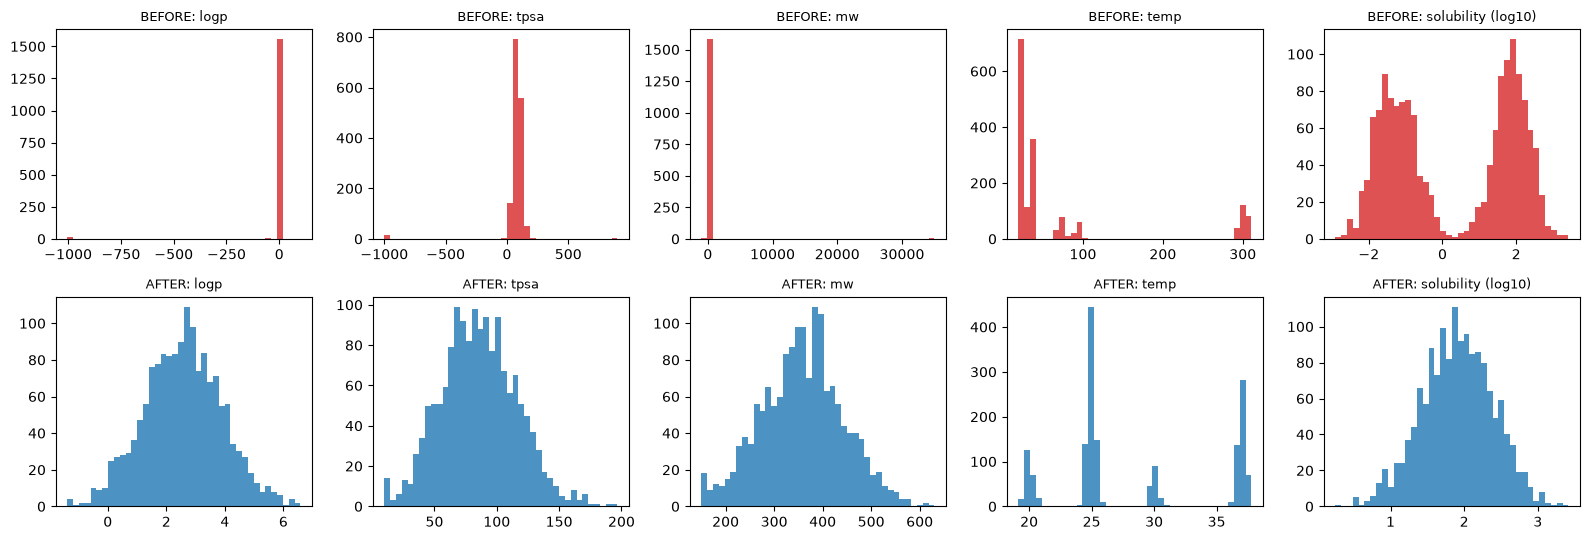

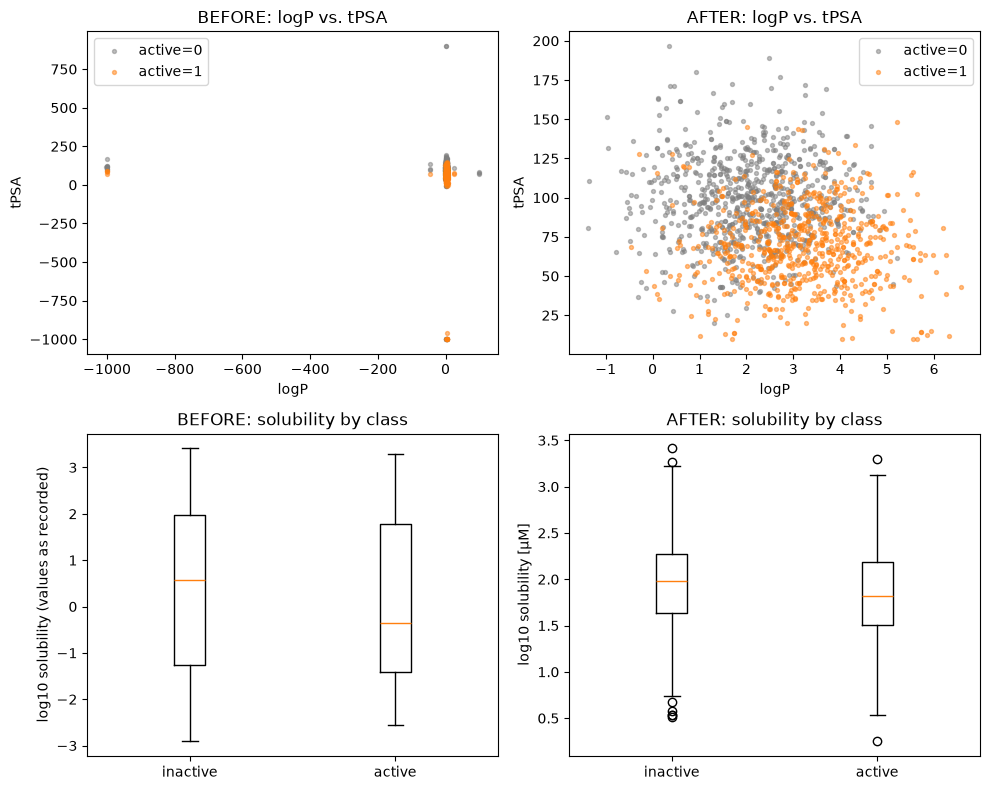

In [26]:
def plot_distributions(before, after, cols=("logp", "tpsa", "mw", "temp", "solubility")):
    fig, axes = plt.subplots(2, len(cols), figsize=(3.2 * len(cols), 5.5))
    for j, c in enumerate(cols):
        for i, (d, name, colr) in enumerate([(before, "BEFORE", "tab:red"), (after, "AFTER", "tab:blue")]):
            x = d[c].dropna()
            if c == "solubility":
                x = np.log10(x[x > 0])
            axes[i, j].hist(x, bins=40, color=colr, alpha=0.8)
            axes[i, j].set_title(f"{name}: {c}" + (" (log10)" if c == "solubility" else ""), fontsize=9)
    plt.tight_layout(); plt.show()


def plot_patterns(before, after):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for k, (d, name) in enumerate([(before, "BEFORE"), (after, "AFTER")]):
        ax = axes[0, k]
        for lab, colr in [(0, "tab:grey"), (1, "tab:orange")]:
            s = d[d["active"] == lab]
            ax.scatter(s["logp"], s["tpsa"], s=8, alpha=0.5, c=colr, label=f"active={lab}")
        ax.set_xlabel("logP"); ax.set_ylabel("tPSA"); ax.set_title(f"{name}: logP vs. tPSA"); ax.legend()
        ax = axes[1, k]
        sol = d["solubility"].where(d["solubility"] > 0)
        data = [np.log10(sol[d["active"] == lab].dropna()) for lab in (0, 1)]
        ax.boxplot(data, tick_labels=["inactive", "active"])
        ax.set_ylabel("log10 solubility (values as recorded)" if k == 0 else "log10 solubility [µM]")
        ax.set_title(f"{name}: solubility by class")
    plt.tight_layout(); plt.show()


before = pd.DataFrame({
    "logp": pd.to_numeric(raw["LogP"], errors="coerce"),
    "tpsa": pd.to_numeric(raw["tPSA [A^2]"], errors="coerce"),
    "mw": pd.to_numeric(raw["MW (g/mol)"].astype(str).str.replace("g/mol", "", regex=False), errors="coerce"),
    "temp": raw["Temp"],
    "solubility": pd.to_numeric(raw["Solubility"], errors="coerce"),
    "active": raw["Active?"].astype(str).str.strip().str.lower().isin(["active", "1", "yes"]).astype(int),
})
after = df.rename(columns={"temp_c": "temp", "solubility_um": "solubility", "is_active": "active"})

plot_distributions(before, after)
plot_patterns(before, after)

**Questions**

1. Which axes changed the most between BEFORE and AFTER? Which single problem caused this?
2. In the logP-vs-tPSA scatter plot: what pattern separates active from inactive compounds, and why was it
   hard to see before?
3. In the solubility boxplot: why do active and inactive compounds look identical BEFORE, and different AFTER?
4. The temperature histogram BEFORE shows several clusters. Which values belong to which unit?
5. Is a value of `logP = 6.5` an outlier that should be removed? How did we decide the limits in Part 6?

**Answers**

1.  The axes for MW, logP and tPSA changed the most due to placeholders and impossible values (ie -999) being kept as numbers. Thus, the real data set in one narrow bar in every  BEFORE histogram

2. In AFTER, the classes separate along a diagonal. Active compounds (orange) sit toward higher logP and lower tPSA (lower right). Inactive compounds (grey) sit toward lower logP and higher tPSA (upper left). The classes overlap, but the trend is clear. In BEFORE, the -999 and -1000 values stretched both axes to about 2000 units wide. All the real compounds were squeezed into a thin vertical line at logP ≈ 0, so no spread and no pattern was visible. The two clumps at x = -1000 are the sentinel rows.

3. In BEFORE, the values were in mixed units. The same compound could appear as 0.05 or 50, so the log10 values spread over about 6 units within each class. That unit noise has nothing to do with activity, and it swamps any real difference. The medians differ only because of how the units happen to fall in each group, not because of chemistry. In AFTER, everything is in µM, so the spread is real. The active median is slightly lower than the inactive, which fits actives being more lipophilic. The difference is modest and the boxes overlap, so it is a trend, not a clean separation.

4.  About 19 to 38: Celsius (C, °C, c).
    About 65 to 100: Fahrenheit (F, °F).
    About 290 to 311: Kelvin (K, kelvin).

5. No, logP = 6.5 is not an outlier and is kept: the Part 6 limits are fixed plausibility ranges (logP between -5 and 10), not statistical cutoffs, so only impossible values like -999 or 99.9 are removed.    






## Part 8 – Does the cleaning improve a Random Forest?

**Task:** predict `is_active` from the measured properties.

The helper below evaluates a Random Forest with 5-fold cross-validation, repeated 3 times. It reports the
mean accuracy in two ways:

* **random CV** – rows are split randomly (what most people do by default)
* **grouped CV** – all rows of the same compound end up in the same fold, so a compound is never in the
  training *and* the test set

Missing values are imputed (median) *inside* the pipeline, i.e. separately in each training fold.

In [27]:
def evaluate(X, y, groups, n_estimators=200, repeats=3):
    """Returns (accuracy with random CV, accuracy with grouped CV), each as mean over folds and repeats."""
    model = make_pipeline(SimpleImputer(strategy="median"),
                          RandomForestClassifier(n_estimators, random_state=0, n_jobs=-1))
    rnd = cross_val_score(model, X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=0))
    grp = []
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r)
        grp.append(cross_val_score(model, X, y, cv=cv, groups=groups).mean())
    return rnd.mean(), float(np.mean(grp))

### 8.1 Baseline: the 'quick and dirty' pipeline on the raw data

In [28]:
# Quick-and-dirty: drop ID/notes/date, convert whatever can be converted, one-hot encode the rest
X_raw = raw.drop(columns=["Compound ID", "Notes", "Measurement Date", "Project", "Active?"]).copy()
for c in X_raw.columns:
    conv = pd.to_numeric(X_raw[c], errors="coerce")
    if conv.notna().mean() > 0.5:
        X_raw[c] = conv
X_raw = pd.get_dummies(X_raw)
y_raw = raw["Active?"].astype(str).str.strip().str.lower().isin(["active", "1", "yes"]).astype(int)

acc_raw = evaluate(X_raw, y_raw, groups=raw["Compound ID"])
print(f"RAW data   ->  {X_raw.shape[1]} features | random CV: {acc_raw[0]:.3f} | grouped CV: {acc_raw[1]:.3f}")

RAW data   ->  58 features | random CV: 0.818 | grouped CV: 0.789


**Before you continue:** how many features did `get_dummies` create from the raw data and why?
Which features did the Random Forest "see" for temperature and solubility?

get_dummies created 50 new columns (58 features in total with the 8 numeric ones). It makes one column per distinct text value, and the inconsistent spellings inflate the count: operator gives 24 columns for 4 people, Method 14 for 3 methods, Temp_unit 7 for 3 units, and Solubilty unit 5 for 3 units.

The Random Forest sees the following: 
Temperature: One Temp column mixing °C (about 19-37), °F (67-100) and K (292-311), plus 7 unit dummies.
Solubility: One Solubility column mixing mg/mL, mM and µM values (with -999 kept as a number), plus 5 unit dummies.

### 8.2 Your cleaned data – three scenarios

Build the feature matrix from `df`: the seven numeric `FEATURES` plus the one-hot encoded `method`
(`pd.get_dummies(df["method"], dtype=float)`). Then evaluate three versions of the training data:

* **A** – cleaned columns and units, but keep duplicates and QC-flagged rows
* **B** – A, but remove duplicates (`is_duplicate`)
* **C** – B, but also remove rows with a QC issue (`qc_issue`)

Define each scenario as a boolean row mask (this is exactly what the flag columns are for!).

In [32]:
X_all = pd.concat([df[FEATURES], pd.get_dummies(df["method"], dtype=float)], axis=1)
y_all = df["is_active"]

# TODO: define the three masks and fill the results dict
masks = {
    "A: cleaned, keep duplicates + QC rows": pd.Series(True, index=df.index),
    "B: A without duplicates": ~df["is_duplicate"],
    "C: B without QC-flagged rows": (~df["is_duplicate"]) & (~df["qc_issue"]),
}


results = {"RAW (quick and dirty)": acc_raw}
for name, m in masks.items():
    results[name] = evaluate(X_all[m], y_all[m], groups=df.loc[m, "compound_id"])

res = pd.DataFrame(results, index=["random CV", "grouped CV"]).T.round(3)
res



,random CV,grouped CV
RAW (quick and dirty),0.818,0.789
"A: cleaned, keep duplicates + QC rows",0.843,0.816
B: A without duplicates,0.817,0.817
C: B without QC-flagged rows,0.836,0.842


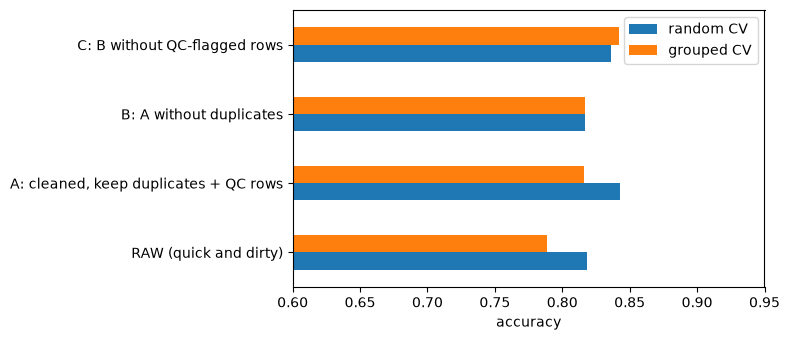

In [33]:
res.plot.barh(figsize=(8, 3.5)); plt.xlim(0.6, 0.95); plt.xlabel("accuracy"); plt.tight_layout(); plt.show()

**Questions**

1. Compare RAW and B in the *grouped CV* column. How many accuracy points did the cleaning of units, glitches and
   categories buy you?
2. Compare A and B in the *random CV* column: the accuracy goes **down** when duplicates are removed. Is B worse?
   Which of the two numbers can you trust, and why? (Hint: what happens when a compound appears in the training
   *and* the test fold?)
3. What does removing the QC-flagged rows (C) improve, and what is the price? Would you also remove such rows from
   the *test* set in a real project?
4. Re-run the notebook after changing the outlier limits in Part 6 (e.g. logP −1…7). What happens?

1. RAW vs B (grouped CV): accuracy rises from 0.789 to 0.817, so the cleaning bought about 2.8 points.

2. A vs B (random CV): B is not worse, and B’s 0.817 is the number to trust. In A, the same compound can sit in both training and test folds (60 exact copies and 75 near-copies), so the model is partly tested on data it has already seen. That inflates A’s 0.843. Once duplicates are removed, random and grouped CV agree (0.817 and 0.817), as expected.

3. C (removing QC-flagged rows):
    Gain: accuracy rises by about 2.5 points in grouped CV (0.817 to 0.842), because contaminated or pipetting-error measurements are noisy.
    Price: fewer rows, and the score is measured on an easier, cleaner subset, so it is not directly comparable.
    Real project: I would remove them from training but not from the test set. Future samples will also have such problems, so the test set should reflect that.

4. A -1 to 7 window would turn the few valid values below -1 into NaN. Those would be median-imputed. This leads to a small change in accuracy and a few more rows flagged is_outlier.

### 8.3 Feature importance before vs. after

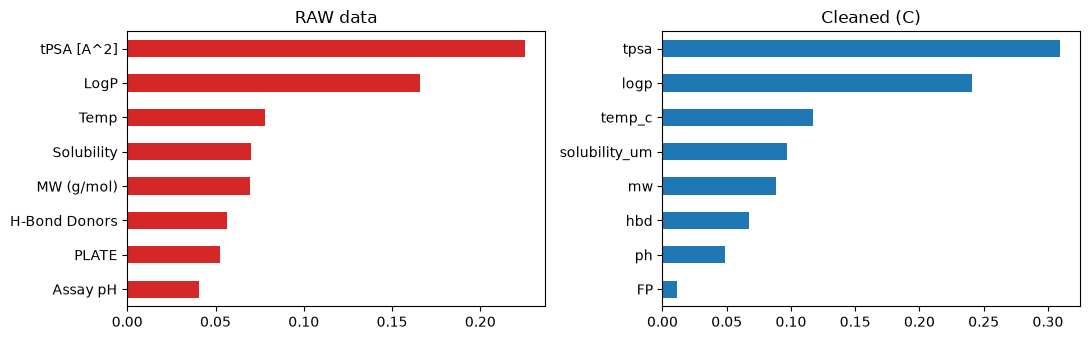

In [35]:

def top_importances(X, y, k=8):
    X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X), columns=X.columns) # RF cannot handle NaNs - fill with median

    # TODO: fit a Random Forest on (a) the RAW features and (b) scenario C and plot the 8 most important features side by side
    #       (hint: model.feature_importances_, pd.Series(..., index=X.columns).nlargest(8))

    model = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
    model.fit(X, y)
    return pd.Series(model.feature_importances_, index=X.columns).nlargest(k)

# plotting
mC = masks["C: B without QC-flagged rows"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
top_importances(X_raw, y_raw).sort_values().plot.barh(ax=axes[0], color="tab:red", title="RAW data")
top_importances(X_all[mC], y_all[mC]).sort_values().plot.barh(ax=axes[1], color="tab:blue", title="Cleaned (C)")
plt.tight_layout(); plt.show()

**Questions:** Which features does the model rely on in the raw data (hint: look at `Temp`, `Solubility`, `PLATE`)?
Are the same features important after cleaning? Is a high importance for `PLATE` or the compound ID a good sign?

**Answers**
1. For raw data, the model relies most on tPSA and LogP, then Temp, Solubility and MW. PLATE (about 0.05) ranks above Assay pH and is close to H-Bond Donors, so the model is using it. Temp and Solubility here are mixed-unit columns, so part of their importance is likely unit and batch artifacts, not real signal.

2. After cleaning, the top features are the same, but their importances are higher and more focused. The scale is not directly comparable between the plots, because importances are shares that sum to one. PLATE is no longer a feature, and FP (a Method dummy) has only a tiny importance.

3. High importance for PLATE or compound ID is not a good sign - They are labels with no chemical meaning. If the model relies on them, it is picking up batch effects or memorising compounds, which would not carry over to new compounds. Healthy importance goes to measured properties such as tPSA and logP, which also match the pattern in the logP vs tPSA scatter plot.

## Part 9 – Bonus challenges

1. **Impute vs. drop.** Compare dropping all rows with missing features to median imputation, and to
   imputation + the `has_missing_feature` flag as an additional feature.
2. **Flags as features.** Add `is_below_lod` as a feature. Does it help? Why might "below LOD" be informative?
3. **Re-measurements.** Instead of keeping only the first entry per compound, average the numeric columns of
   repeated measurements (`groupby("compound_id")`). Does the accuracy change?
4. **Pipeline.** Turn Parts 2–6 into one function `clean(raw) -> df` and test it on a second dataset:
   `python generate_messy_data.py 7` writes a new file with a different random seed. Does your function
   still work without changes? (What did you hard-code?)
5. **Honest evaluation.** Hold out 20 % of the compounds *before* any cleaning decision that uses the labels
   (e.g. QC removal) and report the final accuracy only once on this untouched test set.